# **MODIFIED METHODS**

> modified methods for this research, three machine learning models were trained using two separate dataset.
`raw data` which contains raw concrete ingredients and `enhaced-data` which contains engneering -based features.

```python
X_raw_data = ['cement', 'blast_furnace_slag', 'fly_ash', 'water', 'superplasticizer',
       'coarse_aggregate', 'fine_aggregate', 'age']

eng_fea = ["w/c", "binder", "w/b", "agg_ratio"]
X_eng_data = raw_data + eng_fea

y = ["compressive_strength"]

```

The machine learning models include:
1. Linear Regression Model
2. Random Forest and 
3. XGBoost Regression



importing libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error


In [2]:

#loading dataset
raw_data = pd.read_csv("../data/raw_data.csv")
eng_data = pd.read_csv("../data/eng_data.csv")

raw_data.head()

,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,compressive_strength
0,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
1,266.0,114.0,0.0,228.0,0.0,932.0,670.0,90,47.029847
2,380.0,95.0,0.0,228.0,0.0,932.0,594.0,28,36.447770
3,266.0,114.0,0.0,228.0,0.0,932.0,670.0,28,45.854291
4,475.0,0.0,0.0,228.0,0.0,932.0,594.0,28,39.289790


In [3]:
# Features
X_raw = raw_data.drop("compressive_strength", axis = 1).values
X_eng = eng_data.drop("compressive_strength", axis=1).values

# Label
y = raw_data["compressive_strength"].values


In [4]:

# Create common indices
indices = np.arange(len(y))

train_idx, test_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=100
)

# Raw features
X_train_raw = X_raw[train_idx]
X_test_raw = X_raw[test_idx]

# Engineering-informed features
X_train_eng = X_eng[train_idx]
X_test_eng = X_eng[test_idx]

# Target
y_train = y[train_idx]
y_test = y[test_idx]

print("Training samples:", len(y_train))
print("Testing samples:", len(y_test))

Training samples: 728
Testing samples: 183


In [5]:
# cross validation

from sklearn.model_selection import KFold

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=100
)

print(cv)

KFold(n_splits=5, random_state=100, shuffle=True)


In [6]:
# model definitions

# 1. Linear Regression — Baseline model
lr = LinearRegression()


# 2. Random Forest — Base model
rf = RandomForestRegressor(
    random_state=100,
    n_jobs=-1
)

# 3. XGBoost — Base model
xgb = XGBRegressor(
    objective="reg:squarederror",
    random_state=100,
    n_jobs=-1
)

## **Hyperparameters optimizations**

In [7]:
# search for best hyperparameters for Random Forest and XGBoost using RandomizedSearchCV

rf_param_grid = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [None, 5, 10, 15, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": [1.0, "sqrt", "log2"]
}

xgb_param_grid = {
    "n_estimators": [100, 200, 300, 500],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "max_depth": [2, 3, 4, 5, 6],
    "min_child_weight": [1, 3, 5],
    "subsample": [0.7, 0.8, 1.0],
    "colsample_bytree": [0.7, 0.8, 1.0]
}


import RandomizedSearchCV

In [8]:
from sklearn.model_selection import RandomizedSearchCV

In [9]:
def tune_model(model, param_grid, X_train, y_train, cv):

    search = RandomizedSearchCV(
        estimator=model,
        param_distributions=param_grid,
        n_iter=50,
        scoring="neg_root_mean_squared_error",
        cv=cv,
        random_state=100,
        n_jobs=-1,
        refit=True
    )

    search.fit(X_train, y_train)

    return search

In [10]:
rf_raw_search = tune_model(
    rf,
    rf_param_grid,
    X_train_raw,
    y_train,
    cv
)

rf_eng_search = tune_model(
    rf,
    rf_param_grid,
    X_train_eng,
    y_train,
    cv
)

In [11]:
print("Best RF Raw parameters:")
print(rf_raw_search.best_params_)

print("\nBest RF Engineering parameters:")
print(rf_eng_search.best_params_)

Best RF Raw parameters:
{'n_estimators': 500, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 1.0, 'max_depth': None}

Best RF Engineering parameters:
{'n_estimators': 500, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 1.0, 'max_depth': None}


In [12]:
xgb_raw_search = tune_model(
    xgb,
    xgb_param_grid,
    X_train_raw,
    y_train,
    cv
)

xgb_eng_search = tune_model(
    xgb,
    xgb_param_grid,
    X_train_eng,
    y_train,
    cv
)



print("Best XGB Raw parameters:")
print(xgb_raw_search.best_params_)

print("\nBest XGB Engineering parameters:")
print(xgb_eng_search.best_params_)

Best XGB Raw parameters:
{'subsample': 0.7, 'n_estimators': 500, 'min_child_weight': 3, 'max_depth': 5, 'learning_rate': 0.1, 'colsample_bytree': 0.7}

Best XGB Engineering parameters:
{'subsample': 0.7, 'n_estimators': 300, 'min_child_weight': 5, 'max_depth': 4, 'learning_rate': 0.1, 'colsample_bytree': 1.0}


In [13]:
print("RF Raw CV RMSE:",
      -rf_raw_search.best_score_)

print("RF Engineering CV RMSE:",
      -rf_eng_search.best_score_)

print("XGB Raw CV RMSE:",
      -xgb_raw_search.best_score_)

print("XGB Engineering CV RMSE:",
      -xgb_eng_search.best_score_)

RF Raw CV RMSE: 5.425333861959644
RF Engineering CV RMSE: 5.1864350637051695
XGB Raw CV RMSE: 4.683110663200924
XGB Engineering CV RMSE: 4.386165061939141


In [14]:
# Linear Regression — Raw features
lr_raw = LinearRegression()
lr_raw.fit(X_train_raw, y_train)

# Linear Regression — Engineering-informed features
lr_eng = LinearRegression()
lr_eng.fit(X_train_eng, y_train)


,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


best models based on turned hyperparameters

In [15]:
# final models

rf_raw_final = rf_raw_search.best_estimator_
rf_eng_final = rf_eng_search.best_estimator_

xgb_raw_final = xgb_raw_search.best_estimator_
xgb_eng_final = xgb_eng_search.best_estimator_

In [16]:
predictions = {
    "LR_raw": lr_raw.predict(X_test_raw),
    "RF_raw": rf_raw_final.predict(X_test_raw),
    "XGB_raw": xgb_raw_final.predict(X_test_raw),

    "LR_eng": lr_eng.predict(X_test_eng),
    "RF_eng": rf_eng_final.predict(X_test_eng),
    "XGB_eng": xgb_eng_final.predict(X_test_eng)
}

In [17]:
results = []

for model_name, y_pred in predictions.items():

    r2 = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)

    results.append({
        "Model": model_name,
        "R2": r2,
        "RMSE": rmse,
        "MAE": mae
    })

results_df = pd.DataFrame(results)

results_df

,Model,R2,RMSE,MAE
0,LR_raw,0.754813,7.964342,6.177750
1,RF_raw,0.933921,4.134594,3.113396
2,XGB_raw,0.954548,3.429077,2.529045
3,LR_eng,0.759747,7.883798,6.062939
4,RF_eng,0.941136,3.902349,2.912416
5,XGB_eng,0.958900,3.260793,2.366242


In [18]:
results_df = results_df.copy()

# Extract raw and engineering results
raw_results = results_df[results_df["Model"].str.endswith("_raw")].copy()
eng_results = results_df[results_df["Model"].str.endswith("_eng")].copy()

# Remove feature-type suffix
raw_results["Model"] = raw_results["Model"].str.replace("_raw", "", regex=False)
eng_results["Model"] = eng_results["Model"].str.replace("_eng", "", regex=False)

# Rename columns
raw_results = raw_results.rename(columns={
    "R2": "R2_Raw",
    "RMSE": "RMSE_Raw",
    "MAE": "MAE_Raw"
})

eng_results = eng_results.rename(columns={
    "R2": "R2_Engineering",
    "RMSE": "RMSE_Engineering",
    "MAE": "MAE_Engineering"
})

# Merge
comparison_df = pd.merge(
    raw_results,
    eng_results,
    on="Model"
)

comparison_df

,Model,R2_Raw,RMSE_Raw,MAE_Raw,R2_Engineering,RMSE_Engineering,MAE_Engineering
0,LR,0.754813,7.964342,6.177750,0.759747,7.883798,6.062939
1,RF,0.933921,4.134594,3.113396,0.941136,3.902349,2.912416
2,XGB,0.954548,3.429077,2.529045,0.958900,3.260793,2.366242


In [19]:
comparison_df["R2_Improvement_%"] = (
    (comparison_df["R2_Engineering"] - comparison_df["R2_Raw"])
    / comparison_df["R2_Raw"]
) * 100

comparison_df["RMSE_Improvement_%"] = (
    (comparison_df["RMSE_Raw"] - comparison_df["RMSE_Engineering"])
    / comparison_df["RMSE_Raw"]
) * 100

comparison_df["MAE_Improvement_%"] = (
    (comparison_df["MAE_Raw"] - comparison_df["MAE_Engineering"])
    / comparison_df["MAE_Raw"]
) * 100

comparison_df.round(4)

,Model,R2_Raw,RMSE_Raw,MAE_Raw,R2_Engineering,RMSE_Engineering,MAE_Engineering,R2_Improvement_%,RMSE_Improvement_%,MAE_Improvement_%
0,LR,0.7548,7.9643,6.1777,0.7597,7.8838,6.0629,0.6537,1.0113,1.8584
1,RF,0.9339,4.1346,3.1134,0.9411,3.9023,2.9124,0.7725,5.6171,6.4553
2,XGB,0.9545,3.4291,2.5290,0.9589,3.2608,2.3662,0.4559,4.9076,6.4373


In [20]:
best_r2 = results_df.loc[results_df["R2"].idxmax()]
best_rmse = results_df.loc[results_df["RMSE"].idxmin()]
best_mae = results_df.loc[results_df["MAE"].idxmin()]

print("Best R²:")
print(best_r2)

print("\nBest RMSE:")
print(best_rmse)

print("\nBest MAE:")
print(best_mae)

Best R²:
Model     XGB_eng
R2         0.9589
RMSE     3.260793
MAE      2.366242
Name: 5, dtype: object

Best RMSE:
Model     XGB_eng
R2         0.9589
RMSE     3.260793
MAE      2.366242
Name: 5, dtype: object

Best MAE:
Model     XGB_eng
R2         0.9589
RMSE     3.260793
MAE      2.366242
Name: 5, dtype: object


In [21]:
KFold(
    n_splits=5,
    shuffle=True,
    random_state=100
)

KFold(n_splits=5, random_state=100, shuffle=True)

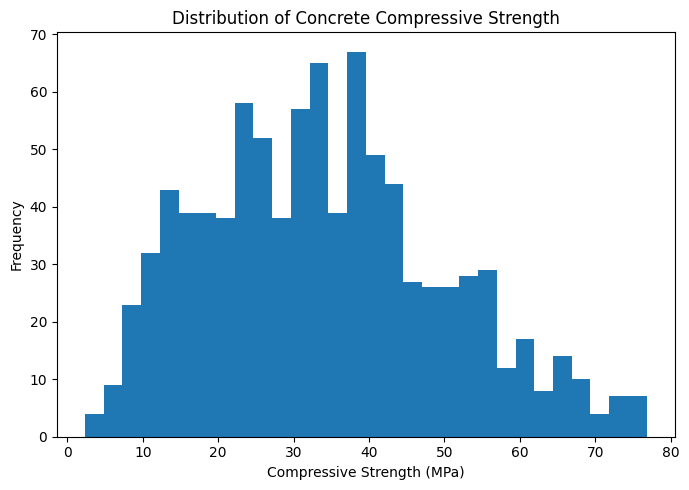

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.hist(y, bins=30)

plt.xlabel("Compressive Strength (MPa)")
plt.ylabel("Frequency")
plt.title("Distribution of Concrete Compressive Strength")

plt.tight_layout()
plt.show()

In [27]:
print("Minimum:", np.min(y))
print("Maximum:", np.max(y))
print("Mean:", np.mean(y))
print("Median:", np.median(y))
print("Standard deviation:", np.std(y))

Minimum: 2.331807832
Maximum: 76.80073164
Mean: 34.03294113131615
Median: 33.0603742
Standard deviation: 15.843539976996214


## **ERROR ANALYSIS**

In [22]:
residuals_df = pd.DataFrame({
    "Experimental": y_test,

    "LR_raw": y_test - predictions["LR_raw"],
    "RF_raw": y_test - predictions["RF_raw"],
    "XGB_raw": y_test - predictions["XGB_raw"],

    "LR_eng": y_test - predictions["LR_eng"],
    "RF_eng": y_test - predictions["RF_eng"],
    "XGB_eng": y_test - predictions["XGB_eng"]
})

residuals_df.head()

,Experimental,LR_raw,RF_raw,XGB_raw,LR_eng,RF_eng,XGB_eng
0,24.448819,7.935402,1.523539,3.008588,7.859618,2.232384,3.792386
1,32.823194,7.301716,1.041645,-0.552870,6.616958,3.320049,2.153381
2,18.198719,-4.706891,-9.159533,-3.030682,-4.074431,-9.308603,-3.171251
3,9.307926,0.619021,0.439674,1.238029,2.471836,0.005050,1.246346
4,30.123206,-0.676397,-1.358189,-1.682349,-1.186642,-2.125147,-2.626332


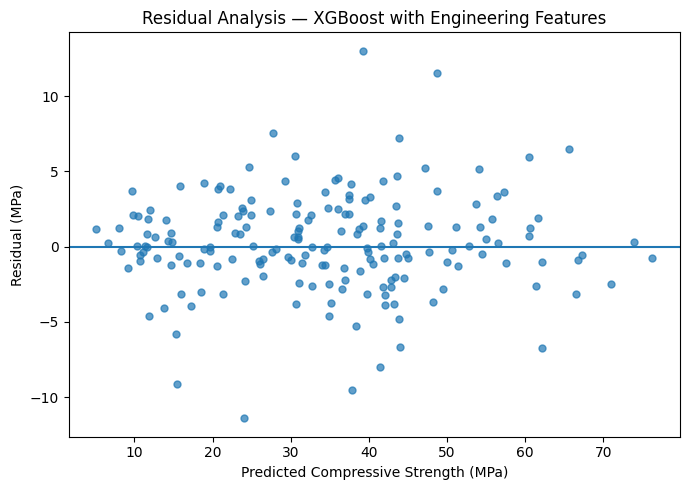

In [27]:
xgb_eng_pred = predictions["XGB_eng"]
xgb_eng_residual = residuals_df["XGB_eng"]

plt.figure(figsize=(7, 5))

plt.scatter(
    xgb_eng_pred,
    xgb_eng_residual,
    s=25,
    alpha=0.7
)

plt.axhline(
    y=0,
    linewidth=1.5
)

plt.xlabel("Predicted Compressive Strength (MPa)")
plt.ylabel("Residual (MPa)")
plt.title("Residual Analysis — XGBoost with Engineering Features")

plt.tight_layout()
plt.show()

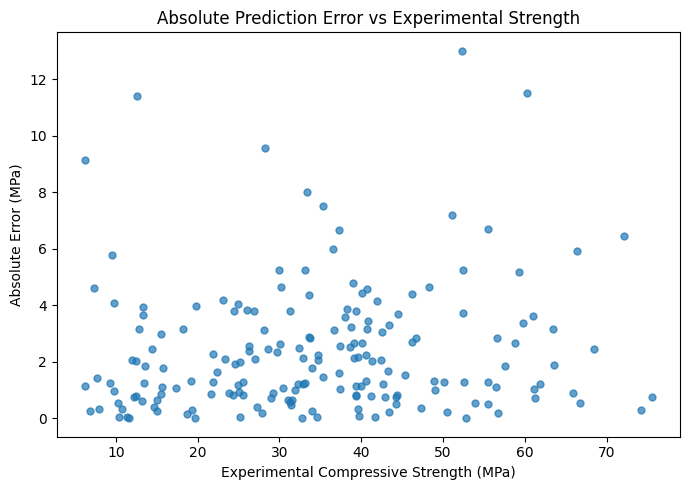

In [28]:
absolute_error = np.abs(
    y_test - predictions["XGB_eng"]
)

plt.figure(figsize=(7, 5))

plt.scatter(
    y_test,
    absolute_error,
    s=25,
    alpha=0.7
)

plt.xlabel("Experimental Compressive Strength (MPa)")
plt.ylabel("Absolute Error (MPa)")
plt.title("Absolute Prediction Error vs Experimental Strength")

plt.tight_layout()
plt.show()

In [29]:
from scipy.stats import pearsonr

corr, p_value = pearsonr(
    y_test,
    absolute_error
)

print(f"Pearson correlation: {corr:.4f}")
print(f"p-value: {p_value:.4f}")

Pearson correlation: 0.1074
p-value: 0.1478


In [30]:
# Create three approximately equal-sized strength groups
strength_groups = pd.qcut(
    y_test,
    q=3,
    labels=["Low", "Medium", "High"]
)

error_analysis = pd.DataFrame({
    "Experimental": y_test,
    "Predicted": predictions["XGB_eng"],
    "Group": strength_groups
})

error_analysis["Error"] = (
    error_analysis["Experimental"] -
    error_analysis["Predicted"]
)

error_analysis["Absolute_Error"] = (
    np.abs(error_analysis["Error"])
)

error_analysis.head()

,Experimental,Predicted,Group,Error,Absolute_Error
0,24.448819,20.656433,Low,3.792386,3.792386
1,32.823194,30.669813,Medium,2.153381,2.153381
2,18.198719,21.369970,Low,-3.171251,3.171251
3,9.307926,8.061580,Low,1.246346,1.246346
4,30.123206,32.749538,Medium,-2.626332,2.626332


In [31]:
group_results = []

for group, data in error_analysis.groupby("Group", observed=True):

    rmse = np.sqrt(
        mean_squared_error(
            data["Experimental"],
            data["Predicted"]
        )
    )

    mae = mean_absolute_error(
        data["Experimental"],
        data["Predicted"]
    )

    r2 = r2_score(
        data["Experimental"],
        data["Predicted"]
    )

    group_results.append({
        "Strength Group": group,
        "N": len(data),
        "R2": r2,
        "RMSE (MPa)": rmse,
        "MAE (MPa)": mae
    })

group_results_df = pd.DataFrame(group_results)

group_results_df

,Strength Group,N,R2,RMSE (MPa),MAE (MPa)
0,Low,61,0.788361,2.860645,1.982931
1,Medium,61,0.343387,3.266943,2.534969
2,High,61,0.852733,3.611387,2.580826


In [32]:
# Divide the test set into three approximately equal-sized strength groups
strength_groups = pd.qcut(
    y_test,
    q=3,
    labels=["Low", "Medium", "High"]
)

error_analysis = pd.DataFrame({
    "Experimental": y_test,
    "Predicted": predictions["XGB_eng"],
    "Group": strength_groups
})

error_analysis["Error"] = (
    error_analysis["Experimental"] -
    error_analysis["Predicted"]
)

error_analysis["Absolute_Error"] = (
    np.abs(error_analysis["Error"])
)

error_analysis.head()

,Experimental,Predicted,Group,Error,Absolute_Error
0,24.448819,20.656433,Low,3.792386,3.792386
1,32.823194,30.669813,Medium,2.153381,2.153381
2,18.198719,21.369970,Low,-3.171251,3.171251
3,9.307926,8.061580,Low,1.246346,1.246346
4,30.123206,32.749538,Medium,-2.626332,2.626332


In [33]:
group_results = []

for group, data in error_analysis.groupby(
    "Group",
    observed=True
):

    rmse = np.sqrt(
        mean_squared_error(
            data["Experimental"],
            data["Predicted"]
        )
    )

    mae = mean_absolute_error(
        data["Experimental"],
        data["Predicted"]
    )

    r2 = r2_score(
        data["Experimental"],
        data["Predicted"]
    )

    group_results.append({
        "Strength Group": group,
        "N": len(data),
        "R2": r2,
        "RMSE (MPa)": rmse,
        "MAE (MPa)": mae
    })

group_results_df = pd.DataFrame(group_results)

group_results_df

,Strength Group,N,R2,RMSE (MPa),MAE (MPa)
0,Low,61,0.788361,2.860645,1.982931
1,Medium,61,0.343387,3.266943,2.534969
2,High,61,0.852733,3.611387,2.580826


In [36]:
bias_results = (
    error_analysis
    .groupby("Group", observed=True)
    .agg(
        N=("Error", "size"),
        Mean_Error=("Error", "mean"),
        Mean_Absolute_Error=("Absolute_Error", "mean")
    )
    .reset_index()
)

bias_results

,Group,N,Mean_Error,Mean_Absolute_Error
0,Low,61,-0.200075,1.982931
1,Medium,61,-0.433337,2.534969
2,High,61,1.321119,2.580826


In [34]:
plot_predictions = {
    "LR_raw": predictions["LR_raw"],
    "RF_raw": predictions["RF_raw"],
    "XGB_raw": predictions["XGB_raw"],
    "LR_eng": predictions["LR_eng"],
    "RF_eng": predictions["RF_eng"],
    "XGB_eng": predictions["XGB_eng"]
}

In [35]:
all_predictions = np.concatenate(
    list(plot_predictions.values())
)

plot_min = min(
    np.min(y_test),
    np.min(all_predictions)
)

plot_max = max(
    np.max(y_test),
    np.max(all_predictions)
)

# Add a small margin
margin = 0.03 * (plot_max - plot_min)

plot_min -= margin
plot_max += margin

print("Plot minimum:", plot_min)
print("Plot maximum:", plot_max)

Plot minimum: -0.38898110822076726
Plot maximum: 78.49871526888136


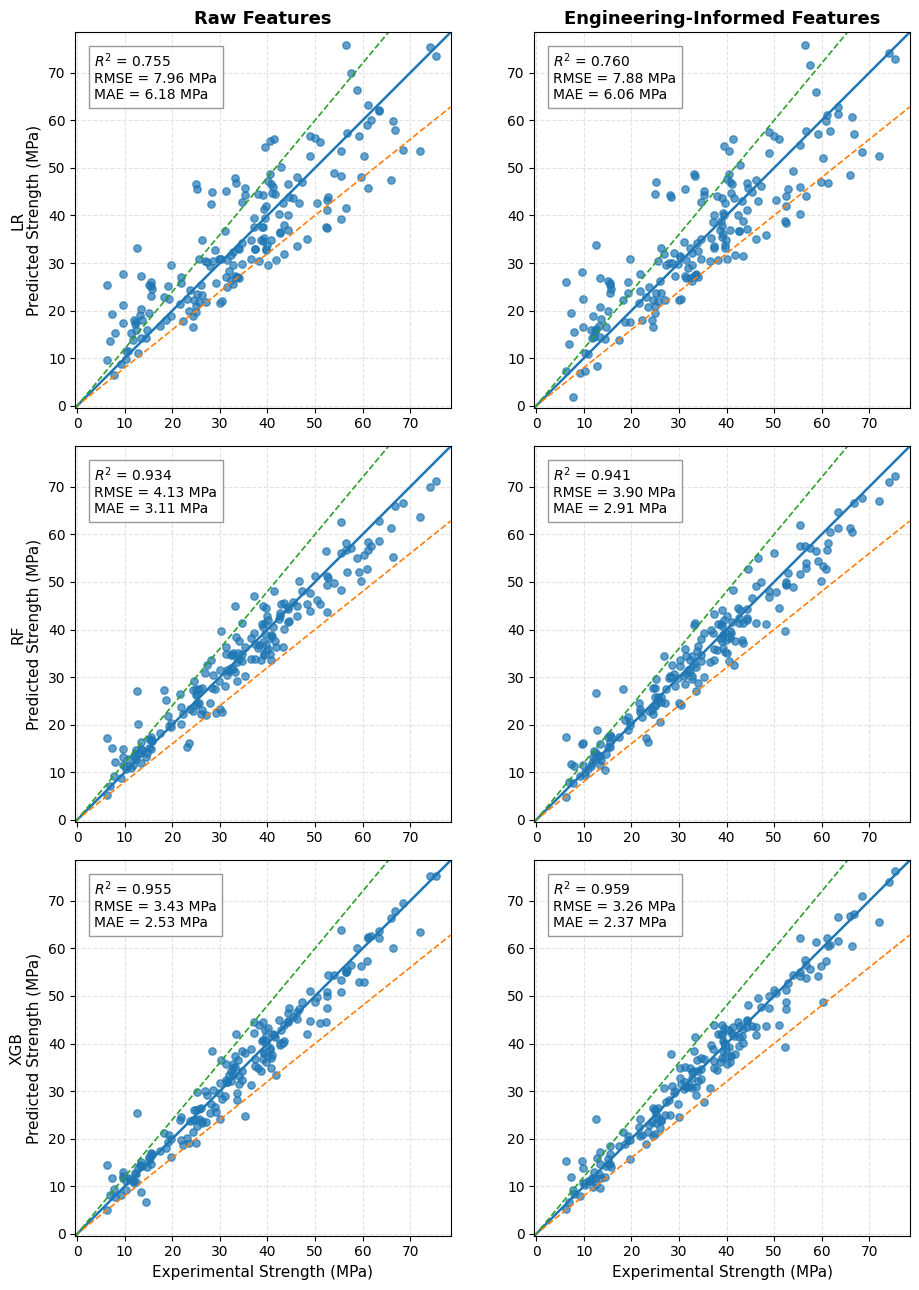

In [46]:
fig, axes = plt.subplots(
    3, 2,
    figsize=(10, 13)
)

models = ["LR", "RF", "XGB"]
feature_types = ["raw", "eng"]

for row, model in enumerate(models):

    for col, feature_type in enumerate(feature_types):

        ax = axes[row, col]

        key = f"{model}_{feature_type}"

        y_pred = predictions[key]

        # -----------------------------
        # Metrics
        # -----------------------------

        r2 = r2_score(y_test, y_pred)

        rmse = np.sqrt(
            mean_squared_error(y_test, y_pred)
        )

        mae = mean_absolute_error(
            y_test, y_pred
        )

        # -----------------------------
        # Scatter plot
        # -----------------------------

        ax.scatter(
            y_test,
            y_pred,
            s=28,
            alpha=0.7
        )

        # -----------------------------
        # Reference lines
        # -----------------------------

        x_line = np.linspace(
            plot_min,
            plot_max,
            200
        )

        # Perfect prediction
        ax.plot(
            x_line,
            x_line,
            linewidth=1.8
        )

        # -20% boundary
        ax.plot(
            x_line,
            0.8 * x_line,
            linestyle="--",
            linewidth=1.2
        )

        # +20% boundary
        ax.plot(
            x_line,
            1.2 * x_line,
            linestyle="--",
            linewidth=1.2
        )

        # -----------------------------
        # Metrics annotation
        # -----------------------------

        ax.text(
            0.05,
            0.95,
            f"$R^2$ = {r2:.3f}\n"
            f"RMSE = {rmse:.2f} MPa\n"
            f"MAE = {mae:.2f} MPa",
            transform=ax.transAxes,
            verticalalignment="top",
            fontsize=10,
            bbox=dict(
                facecolor="white",
                alpha=0.8,
                edgecolor="gray"
            )
        )

        # -----------------------------
        # Titles
        # -----------------------------

        if row == 0:
            title = (
                "Raw Features"
                if feature_type == "raw"
                else "Engineering-Informed Features"
            )

            ax.set_title(
                title,
                fontsize=13,
                fontweight="bold"
            )

        # -----------------------------
        # Axis labels
        # -----------------------------

        if col == 0:
            ax.set_ylabel(
                f"{model}\nPredicted Strength (MPa)",
                fontsize=11
            )

        if row == 2:
            ax.set_xlabel(
                "Experimental Strength (MPa)",
                fontsize=11
            )

        # -----------------------------
        # Formatting
        # -----------------------------

        ax.set_xlim(plot_min, plot_max)
        ax.set_ylim(plot_min, plot_max)

        ax.set_aspect("equal", adjustable="box")

        ax.grid(
            True,
            linestyle="--",
            alpha=0.35
        )


plt.tight_layout()

plt.show()

In [39]:
accuracy_within_limits = []

for model_name, y_pred in predictions.items():

    relative_error = (
        np.abs(y_pred - y_test)
        / np.abs(y_test)
    )

    within_10 = np.mean(
        relative_error <= 0.10
    ) * 100

    within_20 = np.mean(
        relative_error <= 0.20
    ) * 100

    accuracy_within_limits.append({
        "Model": model_name,
        "Within ±10% (%)": within_10,
        "Within ±20% (%)": within_20
    })

accuracy_df = pd.DataFrame(
    accuracy_within_limits
)

accuracy_df.round(2)

,Model,Within ±10% (%),Within ±20% (%)
0,LR_raw,33.33,62.30
1,RF_raw,61.20,89.62
2,XGB_raw,68.31,91.80
3,LR_eng,34.97,60.11
4,RF_eng,65.03,89.62
5,XGB_eng,75.41,92.90


In [22]:
import shap

# Use the optimized and fitted XGBoost model
xgb_eng_final = xgb_eng_search.best_estimator_

# Create SHAP explainer
explainer = shap.TreeExplainer(xgb_eng_final)

# Calculate SHAP values for the test set
shap_values = explainer.shap_values(X_test_eng)

In [36]:
feature_names_eng = [
    "Cement",
    "BFS",
    "FA",
    "water",
    "SP",
    "C-Agg",
    "F-agg",
    "age",
    "w/c",
    "Binder",
    "w/b",
    "agg_ratio"
]

In [37]:
X_train_eng_df = pd.DataFrame(
    X_train_eng,
    columns=feature_names_eng
)

In [38]:
X_test_eng_df = pd.DataFrame(
    X_test_eng,
    columns=feature_names_eng
)

X_test_eng_df.head()

,Cement,BFS,FA,water,SP,C-Agg,F-agg,age,w/c,Binder,w/b,agg_ratio
0,222.36,0.0,96.67,189.29,4.46,967.08,870.32,14.0,0.851277,319.03,0.593330,0.899946
1,380.00,95.0,0.00,228.00,0.00,932.00,594.00,7.0,0.600000,475.00,0.480000,0.637339
2,135.70,203.5,0.00,185.70,0.00,1076.20,759.30,28.0,1.368460,339.20,0.547465,0.705538
3,254.00,0.0,0.00,198.00,0.00,968.00,863.00,3.0,0.779528,254.00,0.779528,0.891529
4,304.80,0.0,99.60,196.00,9.80,959.40,705.20,28.0,0.643045,404.40,0.484669,0.735043


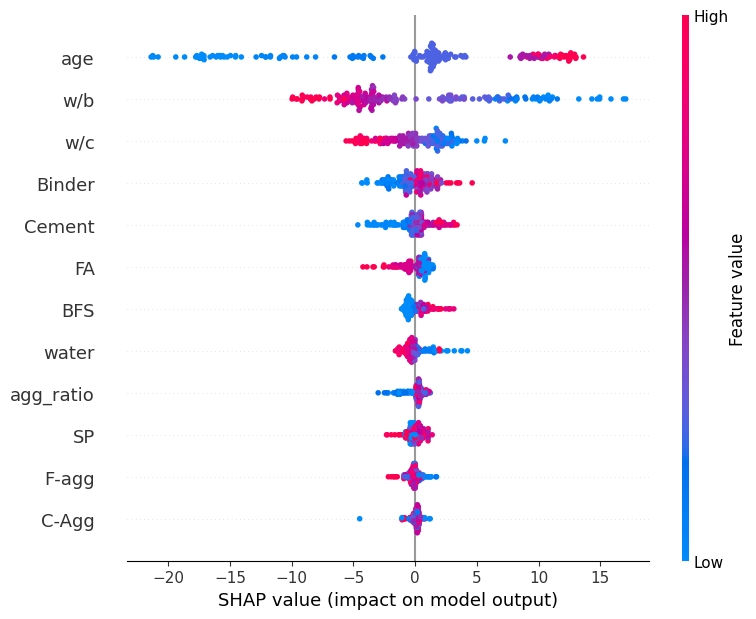

In [39]:
import shap


model = XGBRegressor(n_estimators= 200, learning_rate = 0.05, max_depth = 5)
model.fit(X_train_eng, y_train)

#Initializing shap explainer and computing shap values
explainer = shap.Explainer(model, X_train_eng_df)
shap_values = explainer(X_test_eng_df)

plt.figure(figsize=(8, 6))
shap.summary_plot(shap_values, X_test_eng_df, show=False)
plt.tight_layout()
plt.show()
